In [2]:
pip install akshare

   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 1.1/1.1 MB 18.9 MB/s  0:00:00
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 29.8 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 4.0/4.0 MB 40.5 MB/s  0:00:00
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   ---------------------- ----------------- 8.9/15.5 MB 42.6 MB/s eta 0:00:01
   ---------------------------------------- 15.5/15.5 MB 40.7 MB/s  0:00:00

   -- -------------------------------------  1/17 [webencodings]
   ---- -----------------------------------  2/17 [urllib3]
   ---- -----------------------------------  2/17 [urllib3]
   ------- --------------------------------  3/17 [soupsieve]
   ----------- ----------------------------  5/17 [mini-racer]
   ----------- ---------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import akshare as ak

def get_shebao_holdings(date_str="20260630"):
    """
    获取指定报告期的社保基金持仓
    date_str 格式: 'YYYYMMDD' (如 20260630 代表 2026年中报)
    """
    print(f"正在获取 {date_str} 报告期的社保基金持仓数据...")
    try:
        # 获取东方财富网-特定报告期的机构持仓明细
        # 机构类型包含：券商、基金、QFII、保险、社保等
        df_institution = ak.stock_report_disclosure_cninfo(market="深沪京", period=date_str)
        
        # 过滤出股东名称中包含“社保基金”的记录
        # 注：不同版本的接口字段名可能略有差异，通常包含 '股东名称' 或 '机构名称'
        shebao_df = df_institution[df_institution['十大流通股东'].str.contains('社保基金|全国社保', na=False, regex=True)]
        
        return shebao_df
    except Exception as e:
        print(f"数据获取失败: {e}")
        return pd.DataFrame()

# 示例：对比 2026 一季报 和 2026 年中报，找出连续增持个股
if __name__ == "__main__":
    df_q1 = get_shebao_holdings("20260331")
    df_q2 = get_shebao_holdings("20260630")
    
    if not df_q1.empty and not df_q2.empty:
        # 1. 聚合各股票的社保持仓总量
        q1_total = df_q1.groupby('股票代码')['持股数量(股)'].sum().reset_index(name='Q1_持股')
        q2_total = df_q2.groupby('股票代码')['持股数量(股)'].sum().reset_index(name='Q2_持股')
        
        # 2. 合并两个季度的数据
        merged_df = pd.merge(q1_total, q2_total, on='股票代码', how='inner')
        
        # 3. 筛选环比增持的股票
        increased_stocks = merged_df[merged_df['Q2_持股'] > merged_df['Q1_持股']]
        
        print("\n--- 满足社保基金环比增持的个股 ---")
        print(increased_stocks)


正在获取 20260331 报告期的社保基金持仓数据...
数据获取失败: module 'akshare' has no attribute 'stock_report_disclosure_cninfo'
正在获取 20260630 报告期的社保基金持仓数据...
数据获取失败: module 'akshare' has no attribute 'stock_report_disclosure_cninfo'


In [13]:
import akshare as ak
import pandas as pd

def get_ssf_holdings(report_date: str) -> pd.DataFrame | None:
    print(f"正在获取 {report_date} 报告期的社保基金持仓数据...")
    try:
        # symbol options: 基金持仓 / QFII持仓 / 社保持仓 / 券商持仓 / 保险持仓 / 信托持仓
        df = ak.stock_report_fund_hold(symbol="社保持仓", date=report_date)
        print(f"获取成功: {len(df)} 只股票")
        return df
    except Exception as e:
        print(f"数据获取失败: {e}")
        return None

results = {d: get_ssf_holdings(d) for d in ["20260930"]}


正在获取 20260930 报告期的社保基金持仓数据...
获取成功: 598 只股票


In [19]:
display(results["20260930"].groupby("持股变化").size().reset_index(name="数量"))

,持股变化,数量
0,不变,119
1,减仓,137
2,增仓,197
3,新进,145


In [27]:
display(results["20260930"][results["20260930"]["持股变化"].isin(["新进", "增仓","不变"])])

,序号,股票代码,股票简称,持有基金家数,持股总数,持股市值,持股变化,持股变动数值,持股变动比例
0,1,000680,山推股份,4,95215960,8.626566e+08,增仓,7322600,8.33
1,2,002318,久立特材,4,50713448,9.042208e+08,增仓,2912000,6.09
2,3,002444,巨星科技,4,57979960,1.556182e+09,增仓,3805157,7.02
3,4,000528,柳工,3,37541577,2.823127e+08,增仓,1163800,3.20
5,6,000700,模塑科技,3,40280997,4.946506e+08,增仓,33672697,509.55
...,...,...,...,...,...,...,...,...,...
593,594,688786,悦安新材,1,2071238,5.410074e+07,不变,0,0.00
594,595,688789,宏华数科,1,5547042,2.773521e+08,新进,5547042,NaN
595,596,688808,联讯仪器,1,268462,4.152114e+08,新进,268462,NaN
596,597,688813,泰金新能,1,370456,4.745171e+07,增仓,71050,23.73


In [29]:
df = results["20260930"]
display(
    df[df["持股变化"].isin(["新进", "增仓", "不变"])]
    .sort_values("持股市值", ascending=False).head(50)
)

,序号,股票代码,股票简称,持有基金家数,持股总数,持股市值,持股变化,持股变动数值,持股变动比例
233,234,002594,比亚迪,1,54704200,4.557407e+09,增仓,2963488,5.73
451,452,601899,紫金矿业,1,85798682,2.555943e+09,增仓,4798729,5.92
58,59,300628,亿联网络,2,50057410,1.976767e+09,增仓,8722230,21.10
95,96,601888,中国中免,2,33192098,1.707402e+09,增仓,7993184,31.72
88,89,601058,赛轮轮胎,2,127998380,1.694699e+09,增仓,51935000,68.28
275,276,300124,汇川技术,1,32600000,1.691940e+09,不变,0,0.00
2,3,002444,巨星科技,4,57979960,1.556182e+09,增仓,3805157,7.02
464,465,603087,甘李药业,1,18614962,1.440798e+09,增仓,4637500,33.18
32,33,002027,分众传媒,2,303986001,1.437854e+09,增仓,7166300,2.41
246,247,002714,牧原股份,1,31868817,1.352831e+09,新进,31868817,NaN


In [30]:
display(
    df[df["持股变化"].isin(["新进"])]
    .sort_values("持股市值", ascending=False).head(50)
)

,序号,股票代码,股票简称,持有基金家数,持股总数,持股市值,持股变化,持股变动数值,持股变动比例
246,247,002714,牧原股份,1,31868817,1.352831e+09,新进,31868817,NaN
20,21,603268,松发股份,3,5372140,1.147811e+09,新进,5372140,NaN
33,34,002028,思源电气,2,8267148,9.958606e+08,新进,8267148,NaN
417,418,600958,东方证券,1,115112670,9.957246e+08,新进,115112670,NaN
525,526,603993,洛阳钼业,1,57000000,9.621600e+08,新进,57000000,NaN
469,470,603175,超颖电子,1,9106815,9.512068e+08,新进,9106815,NaN
141,142,000725,京东方A,1,155098200,8.871617e+08,新进,155098200,NaN
62,63,300814,中富电路,2,6610356,8.055380e+08,新进,6610356,NaN
184,185,002050,三花智控,1,21007530,7.501789e+08,新进,21007530,NaN
435,436,601168,西部矿业,1,20825853,7.361939e+08,新进,20825853,NaN


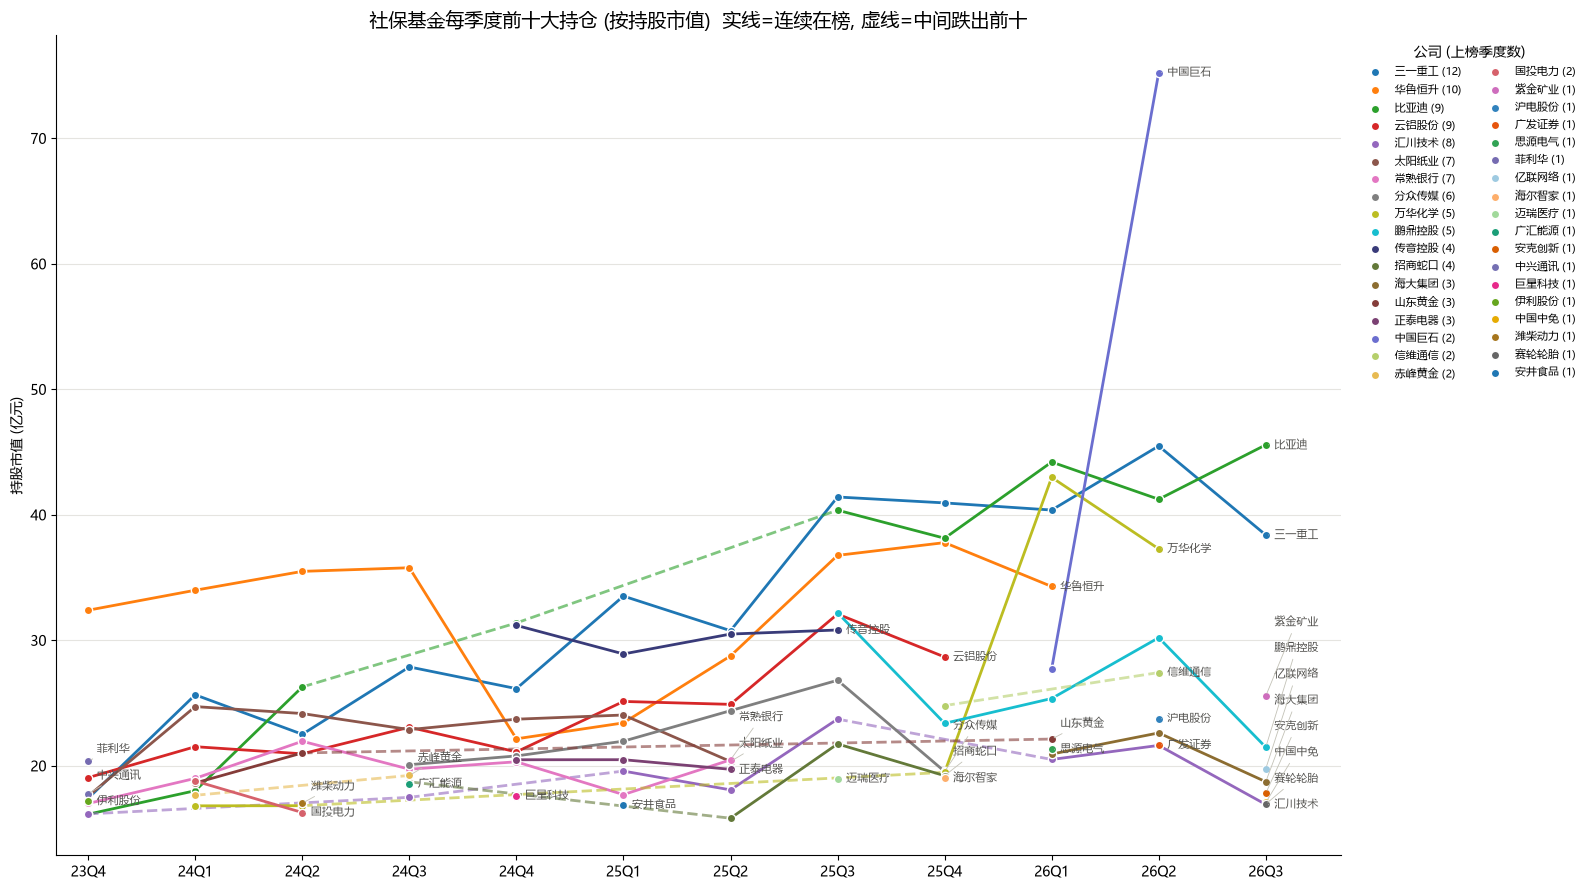

In [32]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 近三年季度报告期: 2023Q4 ~ 2026Q3, 已获取的不重复请求
dates = pd.date_range("2023-12-31", "2026-09-30", freq="QE").strftime("%Y%m%d").tolist()
for d in dates:
    if results.get(d) is None:
        results[d] = get_ssf_holdings(d)

hist = pd.concat(
    [results[d].assign(报告期=pd.Period(d, freq="Q")) for d in dates if results[d] is not None],
    ignore_index=True,
)
hist["持股市值(亿)"] = hist["持股市值"] / 1e8

# 每个报告期按持股市值取前十
top = hist.sort_values("持股市值", ascending=False).groupby("报告期").head(10)
periods = sorted(top["报告期"].unique())
top["x"] = top["报告期"].map({p: i for i, p in enumerate(periods)})
names = hist.sort_values("报告期").groupby("股票代码")["股票简称"].last()

# 上榜次数多的公司优先分配更醒目的颜色; 颜色跟随公司, 不随排名变化
codes = top["股票代码"].value_counts().index.tolist()
palette = (list(plt.cm.tab10.colors)
           + [plt.cm.tab20b.colors[i] for i in (0, 4, 8, 12, 16, 2, 6, 10, 14, 18)]
           + [plt.cm.tab20c.colors[i] for i in (0, 4, 8, 12, 2, 6, 10)]
           + list(plt.cm.Dark2.colors))
colors = {c: palette[i % len(palette)] for i, c in enumerate(codes)}

fig, ax = plt.subplots(figsize=(16, 9))
end_labels = []
for code in codes:
    g = top[top["股票代码"] == code].sort_values("x")
    xs, ys = g["x"].tolist(), g["持股市值(亿)"].tolist()
    color = colors[code]
    # 相邻季度都在前十: 实线; 中间跌出前十: 虚线
    for x0, y0, x1, y1 in zip(xs, ys, xs[1:], ys[1:]):
        gap = x1 - x0 > 1
        ax.plot([x0, x1], [y0, y1], color=color, linewidth=2,
                linestyle="--" if gap else "-", alpha=0.6 if gap else 1)
    ax.scatter(xs, ys, color=color, s=36, zorder=3, edgecolor="white", linewidth=1,
               label=f"{names[code]} ({len(xs)})")
    end_labels.append((xs[-1], ys[-1], names[code]))

# 同一季度的末端标签按 y 排序后拉开最小间距, 避免重叠
min_gap = (top["持股市值(亿)"].max() - top["持股市值(亿)"].min()) * 0.035
for x in {l[0] for l in end_labels}:
    label_y = None
    for _, y, name in sorted([l for l in end_labels if l[0] == x], key=lambda l: l[1]):
        label_y = y if label_y is None else max(y, label_y + min_gap)
        ax.annotate(name, (x, y), xytext=(x + 0.08, label_y), fontsize=8, color="#52514e",
                    va="center", arrowprops=dict(arrowstyle="-", color="#c3c2b7", linewidth=0.6))

ax.set_xticks(range(len(periods)), [f"{p.year % 100}Q{p.quarter}" for p in periods])
ax.set_xlim(-0.3, len(periods) - 0.3)
ax.set_ylabel("持股市值 (亿元)")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(title="公司 (上榜季度数)", bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=8, ncol=2, frameon=False)
ax.set_title("社保基金每季度前十大持仓 (按持股市值)  实线=连续在榜, 虚线=中间跌出前十", fontsize=14)
fig.tight_layout()
plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.express as px
import ipywidgets as widgets
from pathlib import Path
from IPython.display import HTML, display

# 近三年季度报告期: 2023Q4 ~ 2026Q3; 已下载的季度缓存到本地, 重启 kernel 后不必重新下载
dates = pd.date_range("2023-12-31", "2026-09-30", freq="QE").strftime("%Y%m%d").tolist()
cache_path = Path("ssf_holdings_cache.pkl")
cache = pd.read_pickle(cache_path) if cache_path.exists() else {}
for d in dates:
    if results.get(d) is None:
        results[d] = cache[d] if d in cache else get_ssf_holdings(d)
pd.to_pickle({d: results[d] for d in dates if results[d] is not None}, cache_path)

hist = pd.concat(
    [results[d].assign(报告期=pd.Period(d, freq="Q")) for d in dates if results[d] is not None],
    ignore_index=True,
)
hist["持股市值(亿)"] = hist["持股市值"] / 1e8
hist["排名"] = hist.groupby("报告期")["持股市值"].rank(ascending=False, method="first").astype(int)
periods = sorted(hist["报告期"].unique())
quarter_labels = [f"{p.year % 100}Q{p.quarter}" for p in periods]
hist["x"] = hist["报告期"].map(dict(zip(periods, quarter_labels)))
names = hist.sort_values("报告期").groupby("股票代码")["股票简称"].last()

MAX_N = 20
universe = hist[hist["排名"] <= MAX_N]
# 颜色按前20上榜次数固定分配, 过滤时颜色跟随公司不变
order = universe["股票代码"].value_counts().index.tolist()
palette = px.colors.qualitative.Dark24 + px.colors.qualitative.Light24
colors = {c: palette[i % len(palette)] for i, c in enumerate(order)}


def make_fig(top_n, min_quarters, picked):
    top = hist[hist["排名"] <= top_n]
    counts = top["股票代码"].value_counts()
    codes = [c for c in counts.index if counts[c] >= min_quarters and (not picked or c in picked)]

    fig = go.Figure()
    for code in codes:
        g = top[top["股票代码"] == code].sort_values("报告期")
        idx = [quarter_labels.index(q) for q in g["x"]]
        name = f"{names[code]} ({counts[code]})"
        # 实线: 连续季度在榜, 用 None 断开不连续处
        sx, sy, gx, gy = [], [], [], []
        for i, (q, y) in enumerate(zip(g["x"], g["持股市值(亿)"])):
            if i and idx[i] - idx[i - 1] > 1:
                sx.append(None); sy.append(None)
                gx += [g["x"].iloc[i - 1], q, None]; gy += [g["持股市值(亿)"].iloc[i - 1], y, None]
            sx.append(q); sy.append(y)
        fig.add_scatter(
            x=sx, y=sy, mode="lines+markers", name=name, legendgroup=code,
            line=dict(color=colors[code], width=2), marker=dict(size=8, line=dict(color="white", width=1)),
            customdata=[[names[code], code, r, chg] for r, chg in zip(g["排名"], g["持股变化"])],
            hovertemplate="<b>%{customdata[0]}</b> (%{customdata[1]})<br>%{x}  第%{customdata[2]}名"
                          "<br>持股市值 %{y:.1f} 亿<br>持股变化 %{customdata[3]}<extra></extra>",
        )
        # 虚线: 中间跌出前N 的跳跃连接
        if gx:
            fig.add_scatter(x=gx, y=gy, mode="lines", legendgroup=code, showlegend=False,
                            line=dict(color=colors[code], width=2, dash="dash"), opacity=0.6,
                            hoverinfo="skip")

    fig.update_layout(
        title=f"社保基金每季度前{top_n}大持仓 (按持股市值)  实线=连续在榜, 虚线=中间跌出前{top_n}",
        xaxis=dict(categoryorder="array", categoryarray=quarter_labels, type="category"),
        yaxis_title="持股市值 (亿元)", legend_title="公司 (上榜季度数)",
        hovermode="closest", template="plotly_white", height=650,
    )
    return fig


top_n_w = widgets.IntSlider(value=10, min=5, max=MAX_N, description="每季前N")
min_q_w = widgets.IntSlider(value=1, min=1, max=len(periods), description="最少上榜")
pick_w = widgets.SelectMultiple(
    options=[(f"{names[c]} {c}", c) for c in order], rows=8,
    description="公司", layout=widgets.Layout(width="320px"),
)
reset_w = widgets.Button(description="清空公司选择")
reset_w.on_click(lambda _: setattr(pick_w, "value", ()))
out = widgets.Output()


def refresh(*_):
    with out:
        out.clear_output(wait=True)
        # 直接输出 HTML, 不经过 plotly renderer 自动检测 (在 VS Code 的 Output 控件里 fig.show() 可能不显示或卡住)
        fig = make_fig(top_n_w.value, min_q_w.value, set(pick_w.value))
        display(HTML(fig.to_html(full_html=False, include_plotlyjs="cdn")))


for w in (top_n_w, min_q_w, pick_w):
    w.observe(refresh, names="value")
display(widgets.HBox([widgets.VBox([top_n_w, min_q_w, reset_w]), pick_w]), out)
refresh()